# Which components drive MiniRocket's accuracy? A partial reproduction of its sensitivity analysis

**Jacob Antonio and Uchhas Dewan, University College Dublin**

Section 4.3 of Dempster, Schmidt and Webb (2021) examines how MiniRocket's accuracy depends on its main design choices. This notebook documents our partial reproduction of that analysis, which addresses our second research question: which of MiniRocket's components drive its accuracy?

We varied one component at a time, keeping everything else at the paper's defaults:

| Component | Default | Variants we tested | Paper's finding (Section 4.3) |
|---|---|---|---|
| Bias values | Quantiles of the convolution output | Drawn from U(−1, 1), as in Rocket | Sampling from the convolution output is critical; uniform biases are significantly less accurate |
| Pooling | PPV only | PPV plus global max pooling | Adding max pooling gives no benefit, and is slightly (not significantly) worse |
| Number of features | 9,996 | 84, 924 and 4,956 | Accuracy increases noticeably up to about 10,000 features |
| Maximum dilations per kernel | 32 | 8, 16 and 64 | Little difference between 16 and 119 |

The paper also varied kernel length and the subset of kernels used. We did not reproduce those, because they would require rewriting the optimised transform.

**Differences from the paper's setup.** The paper ran this analysis on 40 "development" datasets, using their original train/test splits and averaging 10 runs. We used all 109 UCR datasets from our main reproduction, again on their original splits (identical to the paper's), with `N_RUNS` repeated runs. The paper reports these results only as mean-rank diagrams, without accuracy figures, so we compare our findings with its conclusions rather than with exact numbers.

**Implementation notes.**
- The authors' `minirocket.py` is imported unmodified. The variants are implemented as small separate functions in this notebook.
- For uniform biases, each series is first z-normalised, as Rocket does, because U(−1, 1) biases only make sense on normalised data.
- For max pooling, one global max feature is added per kernel and dilation pair, alongside the unchanged PPV features.
- MiniRocket's bias fitting uses Numba's internal random number generator, which NumPy's seed does not control. Here we seed it explicitly, so each run is repeatable.
- The classifier and feature normalisation are identical to our UCR reproduction.

Results are saved after every dataset, so an interrupted run resumes where it stopped. One run over all variants takes roughly 45 minutes on our machine. `DATASET_LIMIT = 3` gives a quick trial run.

## 1. Configuration and setup

In [1]:
from pathlib import Path
import importlib
import json
import platform
import sys
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
from aeon.datasets import load_from_ts_file
from numba import njit
from scipy.stats import spearmanr, wilcoxon
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits

# Project paths on the machine used for our runs (the same as in our UCR benchmark notebook)
PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
REPO = PROJECT / "minirocket"
CODE_DIR = REPO / "code"
DATA_ROOT = PROJECT / "UCR Archive 2018"
REFERENCE_RESULTS = REPO / "results" / "accuracy_ucr109_resamples.csv"
UCR_SPLIT_DIR = PROJECT / "minirocket_ucr109_results" / "splits"

for required_path in (REPO, CODE_DIR, DATA_ROOT, REFERENCE_RESULTS):
    if not required_path.exists():
        raise FileNotFoundError(f"Required path not found: {required_path}")

# The authors' implementation, imported unmodified
sys.modules.pop("minirocket", None)
sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()
import minirocket

# One CPU thread, as in our reproduction
numba.set_num_threads(1)

DATASET_LIMIT = None  # None runs all 109 datasets; 3 gives a quick trial
N_RUNS = 1            # The paper averaged 10 runs; each extra run adds roughly 45 minutes
BASE_SEED = 2026

OUTPUT_DIR = PROJECT / "minirocket_ablation_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUTPUT_DIR / "ablation_results.csv"
SUMMARY_CSV = OUTPUT_DIR / "ablation_summary.csv"
print("Output folder:", OUTPUT_DIR)

Output folder: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_ablation_results


## 2. Variant implementations

The functions below implement the two variants that need code: biases drawn from U(−1, 1), and PPV plus global max pooling. The max-pooling transform reproduces MiniRocket's own convolution and padding scheme exactly, so its PPV features are identical to the original's; we verified this on synthetic data, with a maximum difference of zero. The remaining variants only change the arguments of the authors' `fit` function.

In [2]:
from numba import njit
import numpy as np


KERNEL_INDICES = np.array(
    [(a, b, c) for a in range(9) for b in range(a + 1, 9) for c in range(b + 1, 9)],
    dtype=np.int32,
)


@njit(cache=False)
def seed_numba(seed):
    # MiniRocket's bias fitting draws training examples with Numba's own random
    # generator, which NumPy's seed does not control. Seeding it here makes runs repeatable.
    np.random.seed(seed)


def zscore(X):
    mean = X.mean(axis=1, keepdims=True)
    std = X.std(axis=1, keepdims=True)
    std[std == 0] = 1.0
    return ((X - mean) / std).astype(np.float32)


def fit_uniform_bias(X, seed, num_features=10_000, max_dilations_per_kernel=32):
    """MiniRocket's dilations, but biases drawn from U(-1, 1) as in Rocket."""
    dilations, num_features_per_dilation = minirocket._fit_dilations(
        X.shape[1], num_features, max_dilations_per_kernel
    )
    n = 84 * int(np.sum(num_features_per_dilation))
    biases = np.random.default_rng(seed).uniform(-1, 1, n).astype(np.float32)
    return dilations, num_features_per_dilation, biases


@njit(fastmath=True, cache=False)
def transform_ppv_max(X, dilations, num_features_per_dilation, biases, indices):
    """MiniRocket's transform, plus one global max feature per kernel/dilation pair."""
    num_examples, input_length = X.shape
    num_kernels = len(indices)
    num_dilations = len(dilations)
    num_ppv = num_kernels * np.sum(num_features_per_dilation)
    features = np.zeros((num_examples, num_ppv + num_kernels * num_dilations), dtype=np.float32)

    for example_index in range(num_examples):
        _X = X[example_index]
        A = -_X
        G = _X + _X + _X
        feature_index_start = 0
        max_index = num_ppv

        for dilation_index in range(num_dilations):
            _padding0 = dilation_index % 2
            dilation = dilations[dilation_index]
            padding = ((9 - 1) * dilation) // 2
            num_features_this_dilation = num_features_per_dilation[dilation_index]

            C_alpha = np.zeros(input_length, dtype=np.float32)
            C_alpha[:] = A
            C_gamma = np.zeros((9, input_length), dtype=np.float32)
            C_gamma[9 // 2] = G

            start = dilation
            end = input_length - padding
            for gamma_index in range(9 // 2):
                C_alpha[-end:] = C_alpha[-end:] + A[:end]
                C_gamma[gamma_index, -end:] = G[:end]
                end += dilation
            for gamma_index in range(9 // 2 + 1, 9):
                C_alpha[:-start] = C_alpha[:-start] + A[start:]
                C_gamma[gamma_index, :-start] = G[start:]
                start += dilation

            for kernel_index in range(num_kernels):
                _padding1 = (_padding0 + kernel_index) % 2
                index_0, index_1, index_2 = indices[kernel_index]
                C = C_alpha + C_gamma[index_0] + C_gamma[index_1] + C_gamma[index_2]
                if _padding1 == 1:
                    C = C[padding:-padding]
                for feature_count in range(num_features_this_dilation):
                    b = biases[feature_index_start + feature_count]
                    count = 0
                    for value in C:
                        if value > b:
                            count += 1
                    features[example_index, feature_index_start + feature_count] = count / len(C)
                features[example_index, max_index] = C.max()
                max_index += 1
                feature_index_start += num_features_this_dilation

    return features

## 3. Datasets

We used the same 109 datasets as our main reproduction, taken from the authors' result file, with each dataset's original UCR train/test split. The classifier and its feature normalisation are identical to those of our main reproduction.

In [3]:
reference = pd.read_csv(REFERENCE_RESULTS)
dataset_names = reference["dataset"].astype(str).tolist()

train_by_name = {}
for train_path in DATA_ROOT.rglob("*_TRAIN.ts"):
    train_by_name.setdefault(train_path.name.removesuffix("_TRAIN.ts"), train_path)

dataset_paths = []
for dataset_name in dataset_names:
    train_path = train_by_name.get(dataset_name)
    if train_path is None or not train_path.with_name(f"{dataset_name}_TEST.ts").exists():
        raise FileNotFoundError(f"Missing UCR train/test files for {dataset_name}")
    dataset_paths.append((dataset_name, train_path, train_path.with_name(f"{dataset_name}_TEST.ts")))

if DATASET_LIMIT is not None:
    dataset_paths = dataset_paths[:DATASET_LIMIT]
print(f"Datasets selected: {len(dataset_paths)}")


def load_univariate_fixed_length(path):
    """Load one UCR .ts file as a float32 array of shape (cases, time points)."""
    X, y = load_from_ts_file(str(path))
    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 3 and X.shape[1] == 1:
        X = X[:, 0, :]
    elif X.ndim != 2:
        raise ValueError(f"Expected univariate fixed-length data; got shape {X.shape}")
    return X, np.asarray(y)


def ridge_accuracy(Xt_train, y_train, Xt_test, y_test):
    """Same classifier and feature normalisation as our UCR reproduction."""
    feature_mean = Xt_train.mean(axis=0)
    Xt_train = Xt_train - feature_mean
    Xt_test = Xt_test - feature_mean
    feature_scale = np.sqrt((Xt_train ** 2).sum(axis=0))
    feature_scale[feature_scale == 0] = 1.0
    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    classifier.fit(Xt_train / feature_scale, y_train)
    return accuracy_score(y_test, classifier.predict(Xt_test / feature_scale))

Datasets selected: 109


## 4. Variants

Each variant is defined by how it fits MiniRocket and transforms the data. All variants share the same seeded random state for a given dataset and run, so the default variant and, for example, the 64-dilation variant draw their bias examples in the same way.

In [4]:
def run_default(Xtr, Xte, seed, **fit_kwargs):
    seed_numba(seed)
    parameters = minirocket.fit(Xtr, **fit_kwargs)
    return minirocket.transform(Xtr, parameters), minirocket.transform(Xte, parameters)


def run_uniform_bias(Xtr, Xte, seed):
    Xtr, Xte = zscore(Xtr), zscore(Xte)
    parameters = fit_uniform_bias(Xtr, seed)
    return minirocket.transform(Xtr, parameters), minirocket.transform(Xte, parameters)


def run_ppv_max(Xtr, Xte, seed):
    seed_numba(seed)
    dilations, per_dilation, biases = minirocket.fit(Xtr)
    return (transform_ppv_max(Xtr, dilations, per_dilation, biases, KERNEL_INDICES),
            transform_ppv_max(Xte, dilations, per_dilation, biases, KERNEL_INDICES))


VARIANTS = {
    "default": lambda Xtr, Xte, s: run_default(Xtr, Xte, s),
    "bias_uniform": run_uniform_bias,
    "ppv_plus_max": run_ppv_max,
    "features_84": lambda Xtr, Xte, s: run_default(Xtr, Xte, s, num_features=84),
    "features_924": lambda Xtr, Xte, s: run_default(Xtr, Xte, s, num_features=924),
    "features_4956": lambda Xtr, Xte, s: run_default(Xtr, Xte, s, num_features=4956),
    "max_dilations_8": lambda Xtr, Xte, s: run_default(Xtr, Xte, s, max_dilations_per_kernel=8),
    "max_dilations_16": lambda Xtr, Xte, s: run_default(Xtr, Xte, s, max_dilations_per_kernel=16),
    "max_dilations_64": lambda Xtr, Xte, s: run_default(Xtr, Xte, s, max_dilations_per_kernel=64),
}
print("Variants:", list(VARIANTS))

Variants: ['default', 'bias_uniform', 'ppv_plus_max', 'features_84', 'features_924', 'features_4956', 'max_dilations_8', 'max_dilations_16', 'max_dilations_64']


## 5. Running the ablation

For each dataset, run and variant, we fit on the original training split, transform both splits and record test accuracy and transform time. Before timing begins, every variant is run once on a small dataset so that Numba's compilation time is excluded. Completed results are read back on restart and skipped.

In [5]:
EXPERIMENT_NAME = "MiniRocket component ablation (partial reproduction of Section 4.3)"
EXPERIMENT_SETTINGS = {"n_runs": N_RUNS, "base_seed": BASE_SEED, "variants": list(VARIANTS),
                       "split": "original UCR train/test split"}

# Untimed warm-up so Numba compilation is not counted
warm_X, _ = load_univariate_fixed_length(dataset_paths[0][1])
for variant_function in VARIANTS.values():
    variant_function(warm_X[:10], warm_X[:10], 0)
print("Warm-up complete.")

rows = pd.read_csv(RESULTS_CSV).to_dict("records") if RESULTS_CSV.exists() else []
completed = {(r["dataset"], int(r["run"]), r["variant"]) for r in rows}
start_time = time.perf_counter()

with threadpool_limits(limits=1):
    for dataset_number, (name, train_path, test_path) in enumerate(dataset_paths, start=1):
        X_train, y_train = load_univariate_fixed_length(train_path)
        X_test, y_test = load_univariate_fixed_length(test_path)
        for run in range(N_RUNS):
            seed = BASE_SEED + 1000 * run + dataset_number
            for variant, variant_function in VARIANTS.items():
                if (name, run, variant) in completed:
                    continue
                t0 = time.perf_counter()
                Xt_train, Xt_test = variant_function(X_train, X_test, seed)
                transform_seconds = time.perf_counter() - t0
                rows.append({
                    "dataset": name, "run": run, "variant": variant, "seed": seed,
                    "accuracy": ridge_accuracy(Xt_train, y_train, Xt_test, y_test),
                    "num_features": Xt_train.shape[1], "transform_seconds": transform_seconds,
                })
        pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)
        print(f"{dataset_number:3}/{len(dataset_paths)} {name}")

print(f"\nFinished in {(time.perf_counter() - start_time) / 60:.1f} minutes. Results: {RESULTS_CSV}")

Warm-up complete.
  1/109 ACSF1
  2/109 Adiac
  3/109 ArrowHead
  4/109 BME
  5/109 Beef
  6/109 BeetleFly
  7/109 BirdChicken
  8/109 CBF
  9/109 Car
 10/109 Chinatown
 11/109 ChlorineConcentration
 12/109 CinCECGTorso
 13/109 Coffee
 14/109 Computers
 15/109 CricketX
 16/109 CricketY
 17/109 CricketZ
 18/109 Crop
 19/109 DiatomSizeReduction
 20/109 DistalPhalanxOutlineAgeGroup
 21/109 DistalPhalanxOutlineCorrect
 22/109 DistalPhalanxTW
 23/109 ECG200
 24/109 ECG5000
 25/109 ECGFiveDays
 26/109 EOGHorizontalSignal
 27/109 EOGVerticalSignal
 28/109 Earthquakes
 29/109 ElectricDevices
 30/109 EthanolLevel
 31/109 FaceAll
 32/109 FaceFour
 33/109 FacesUCR
 34/109 FiftyWords
 35/109 Fish
 36/109 FordA
 37/109 FordB
 38/109 FreezerRegularTrain
 39/109 FreezerSmallTrain
 40/109 GunPoint
 41/109 GunPointAgeSpan
 42/109 GunPointMaleVersusFemale
 43/109 GunPointOldVersusYoung
 44/109 Ham
 45/109 Haptics
 46/109 Herring
 47/109 HouseTwenty
 48/109 InlineSkate
 49/109 InsectEPGRegularTrain
 50/1

## 6. Results

This cell reads only the saved results file, so it can be run on its own in a fresh session. For each variant, it reports mean accuracy over the datasets (averaging runs first), the change from the default, win/draw/loss counts against the default (differences under 0.05 percentage points count as draws), a Wilcoxon signed-rank test against the default, the mean rank across variants, and the total transform time.

109 datasets with all variants complete


,variant,mean_accuracy_%,change_vs_default_points,wins,draws,losses,wilcoxon_p_vs_default,mean_rank,total_transform_seconds
8,ppv_plus_max,85.7900,0.0908,39,42,28,0.1674,3.6789,548.8507
6,max_dilations_64,85.8011,0.1020,35,47,27,0.2954,3.7706,175.5386
1,default,85.6992,0.0000,0,109,0,NaN,4.0046,152.0260
2,features_4956,85.6020,-0.0972,26,38,45,0.0931,4.4037,93.5478
5,max_dilations_16,85.3391,-0.3601,21,50,38,0.0086,4.5092,138.3673
7,max_dilations_8,85.2435,-0.4557,21,39,49,0.0017,4.9220,126.3970
0,bias_uniform,84.4879,-1.2112,25,20,64,0.0000,5.7615,147.6221
4,features_924,84.4651,-1.2341,23,18,68,0.0000,5.7615,25.3577
3,features_84,73.5535,-12.1456,6,8,95,0.0000,8.1881,3.0043


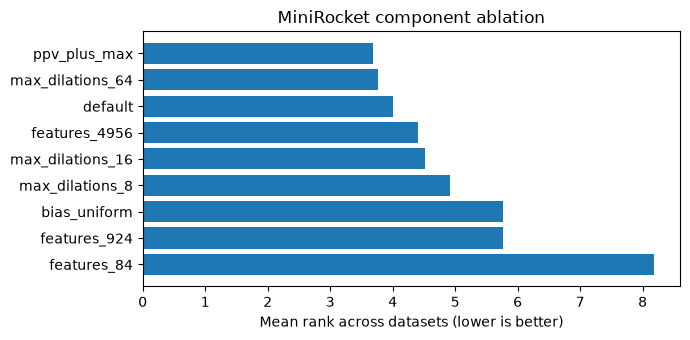

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import wilcoxon

OUTPUT_DIR = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series") / "minirocket_ablation_results"
results = pd.read_csv(OUTPUT_DIR / "ablation_results.csv")

per_dataset = results.groupby(["dataset", "variant"])["accuracy"].mean().unstack()
per_dataset = per_dataset.dropna()  # keep datasets where every variant finished
ranks = per_dataset.rank(axis=1, ascending=False).mean()
times = results.groupby(["dataset", "variant"])["transform_seconds"].mean().unstack().loc[per_dataset.index].sum()

rows = []
for variant in per_dataset.columns:
    difference = per_dataset[variant] - per_dataset["default"]
    try:
        p_value = float("nan") if variant == "default" else wilcoxon(per_dataset[variant], per_dataset["default"]).pvalue
    except ValueError:  # every difference is zero
        p_value = 1.0
    rows.append({
        "variant": variant,
        "mean_accuracy_%": 100 * per_dataset[variant].mean(),
        "change_vs_default_points": 100 * difference.mean(),
        "wins": int((difference > 0.0005).sum()),
        "draws": int((difference.abs() <= 0.0005).sum()),
        "losses": int((difference < -0.0005).sum()),
        "wilcoxon_p_vs_default": p_value,
        "mean_rank": ranks[variant],
        "total_transform_seconds": times[variant],
    })
summary = pd.DataFrame(rows).sort_values("mean_rank")
summary.to_csv(OUTPUT_DIR / "ablation_summary.csv", index=False)
print(f"{len(per_dataset)} datasets with all variants complete")
display(summary.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(summary["variant"], summary["mean_rank"])
ax.invert_yaxis()
ax.set_xlabel("Mean rank across datasets (lower is better)")
ax.set_title("MiniRocket component ablation")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ablation_mean_rank.png", dpi=300)
plt.show()

## 7. Recording the experimental setup

The settings, dataset list, platform and software versions are saved in `experiment_metadata.json` alongside the results.

In [7]:
from importlib.metadata import PackageNotFoundError, version


def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


metadata = {
    "recorded_local_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    "experiment": EXPERIMENT_NAME,
    "settings": EXPERIMENT_SETTINGS,
    "datasets": [name for name, _, _ in dataset_paths],
    "numba_threads": numba.get_num_threads(),
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "software_versions": {p: package_version(p) for p in ("numpy", "pandas", "scikit-learn", "scipy", "aeon", "numba")},
}
(OUTPUT_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Metadata saved to:", OUTPUT_DIR / "experiment_metadata.json")

Metadata saved to: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_ablation_results/experiment_metadata.json
